# 05.02 — Od map uwagi do bloku Transformera

**Rachunek na tablicy i ćwiczenie w NumPy · około 45 minut**

W [ćwiczeniu o liczbie głów](Ch05_01_ile_glow_attention.ipynb) każda głowa tworzyła własną mapę odczytu. Teraz dokładamy trzy operacje. **Residual** dodaje poprawkę do bieżącej reprezentacji. **LayerNorm** porządkuje skalę cech pojedynczego tokenu. **FFN** przekształca cechy każdego tokenu tym samym małym MLP.

Po zajęciach umiesz rozpisać forward bloku pre-LN, przewidzieć kształty i sprawdzić, czy zmiana przyszłego tokenu lub dopisanie PAD wpływa na bieżący wynik. Wagi w demonstracji są ustalone. Do wykonania wystarczą NumPy i Matplotlib na CPU. Dane powstają w pierwszej komórce.

## 1. Od identyfikatorów do wektorów

Niech $i_{b,t}$ oznacza identyfikator tokenu $t$ w próbce $b$. Z dwóch tablic odczytujemy wektor tokenu i wektor pozycji.

$$
X_{b,t} = E[i_{b,t}] + P[t].
$$

$E$ jest tablicą embeddingów tokenów, a $P$ zawiera embeddingi pozycji. Używamy addytywnych pozycji absolutnych. Dwa wystąpienia tego samego tokenu mogą mieć identyczne $E[i]$ i różne $P[t]$. W trenowanym modelu te tablice mogą być uczonymi parametrami.

| Obiekt | Kształt | Co oznaczają osie |
| --- | --- | --- |
| `ids` i `valid` | $(B,T)$ | próbka, pozycja |
| $X$, $R$, $Y$ | $(B,T,D)$ | próbka, pozycja, cecha |
| $Q,K,V$ po podziale | $(B,H,T,d_h)$ | próbka, głowa, pozycja, cecha w głowie |
| $\alpha$ | $(B,H,T,T)$ | próbka, głowa, zapytanie, klucz |
| Ukryta warstwa FFN | $(B,T,D_{\mathrm{ff}})$ | próbka, pozycja, cecha FFN |

$D$ to szerokość bloku, $H$ liczba głów i $d_h=D/H$. Padding pozwala umieścić w jednym batchu sekwencje różnej długości. W demonstracji $B=3$, $T=4$, $D=4$ i $H=2$. Trzeci przykład z samym PAD służy do sprawdzenia przypadku brzegowego.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

names = ("PAD", "kot", "pije", "wodę", "pies", "śpi")
ids = np.array([[1, 2, 3, 0], [4, 5, 0, 0], [0, 0, 0, 0]])
valid = ids != 0
B, T = ids.shape
D, H = 4, 2

rng = np.random.default_rng(6)
E = rng.normal(size=(len(names), D))
P = rng.normal(scale=0.3, size=(T, D))
X = E[ids] + P[None, :, :]

print("Tokeny", np.array(names)[ids].tolist())
print("Długości sekwencji", valid.sum(axis=1).tolist())
print("Kształt X", X.shape)
same_token = E[1] + P[[0, 2]]
print("Różne wektory tego samego tokenu na pozycjach 0 i 2", same_token.round(3).tolist())

Tokeny [['kot', 'pije', 'wodę', 'PAD'], ['pies', 'śpi', 'PAD', 'PAD'], ['PAD', 'PAD', 'PAD', 'PAD']]
Długości sekwencji [3, 2, 0]
Kształt X (3, 4, 4)
Różne wektory tego samego tokenu na pozycjach 0 i 2 [[0.534, 0.833, 0.76, 1.238], [1.282, 1.306, 0.979, 1.339]]


## 2. Kto może odczytać którą pozycję?

Wiersz mapy odpowiada pozycji zapytania $t$, kolumna pozycji klucza $s$. Pozycje liczymy od zera.

1. **Padding klucza** wyklucza $s$, gdy $s$ zawiera PAD. Rzeczywisty token może odczytywać tylko rzeczywiste tokeny.
2. **Maska przyczynowa** dopuszcza $s\le t$. Reprezentacja w pozycji $t$ może używać samego tokenu $t$ i poprzedzającego go prefiksu. Przy predykcji kolejnego tokenu odpowiedź znajduje się dopiero w $t+1$.
3. **Padding zapytania** wyłącza wiersz $t$, gdy $t$ zawiera PAD. Przyjmujemy w takim wierszu wszystkie wagi i wyjście równe zeru.

$$
M_{b,t,s} =
\mathrm{valid}_{b,t} \ \land\  \mathrm{valid}_{b,s}
\ \land\ (s\le t)
\qquad\text{w trybie przyczynowym}.
$$

W trybie dwukierunkowym pozostają oba warunki `valid`. Ta sama maska obowiązuje wszystkie głowy. W kodzie `True` oznacza dostęp. Softmax wykonujemy po osi **klucza**, osobno dla każdego zapytania. Logit wykluczonego klucza zastępujemy przez $-\infty$. Od dostępnych logitów odejmujemy ich maksimum. Ten krok zachowuje wagi softmax i zapobiega przepełnieniu dla dużych skończonych logitów. Dla wiersza bez dostępnego klucza jawnie zwracamy zera, co pozwala pominąć dzielenie przez zero. Suma wag takiego wiersza wynosi zero. Dla aktywnego wiersza wynosi jeden. Przykładowo przy logitach $(1000,999,3000)$ i masce $(1,1,0)$ po odjęciu $1000$ mamy $(0,-1,-\infty)$. Pierwsze dwie wagi to $1/(1+e^{-1})$ i $e^{-1}/(1+e^{-1})$. Waga trzeciego klucza wynosi zero.

Przy macierzach $Q,K,V$ jednej głowy i jej mapie $\alpha$ liczymy

$$
S=QK^\mathsf{T}/\sqrt{d_h},\qquad
\alpha=\operatorname{softmax}_{s}(S\ \text{po maskowaniu}),\qquad
C=\alpha V.
$$

Składamy wyniki $C$ kolejnych głów wzdłuż cech i stosujemy wspólną projekcję $W_O$. Kształt wyjścia attention wraca do $(B,T,D)$.

In [2]:
def attention_mask(valid, causal):
    length = valid.shape[1]
    allowed = valid[:, None, :, None] & valid[:, None, None, :]
    if causal:
        past = np.tril(np.ones((length, length), dtype=bool))
        allowed = allowed & past[None, None, :, :]
    return allowed


def masked_softmax(scores, allowed):
    masked = np.where(allowed, scores, -np.inf)
    largest = masked.max(axis=-1, keepdims=True)
    largest = np.where(allowed.any(axis=-1, keepdims=True), largest, 0.0)
    numerator = np.exp(masked - largest)
    denominator = numerator.sum(axis=-1, keepdims=True)
    return np.divide(
        numerator, denominator, out=np.zeros_like(numerator),
        where=denominator > 0,
    )


# Skrajnie duże logity i pusty wiersz.
test_scores = np.array([[1000.0, 999.0, 3000.0], [5.0, 4.0, 3.0]])
test_mask = np.array([[True, True, False], [False, False, False]])
test_weights = masked_softmax(test_scores, test_mask)
print("Softmax z maską", test_weights.round(4).tolist())
print("Sumy wierszy", test_weights.sum(axis=-1).round(4).tolist())

Softmax z maską [[0.7311, 0.2689, 0.0], [0.0, 0.0, 0.0]]
Sumy wierszy [1.0, 0.0]


## 3. Dwie poprawki do reprezentacji

Blok **pre-LN** normalizuje wejście do każdego z dwóch podbloków. Warstwa normalizacji działa osobno dla każdego tokenu, po jego $D$ cechach. Dla wektora $x$ liczymy

$$
\mathrm{LN}(x) = g\odot \frac{x-\mu}{\sqrt{\sigma^2+\varepsilon}} + \beta,
\quad
\mu=\frac1D\sum_{j=1}^{D} x_j,\quad
\sigma^2=\frac1D\sum_{j=1}^{D}(x_j-\mu)^2.
$$

$g$ i $\beta$ mają po $D$ elementów. $\varepsilon>0$ pozwala obliczyć wynik także przy zerowej wariancji. Wymiary próbki i pozycji pozostają zachowane. Dla porównania BatchNorm na wejściu $(B,D)$ w trakcie treningu liczy statystyki po próbkach, osobno dla każdej cechy. Tutaj każdy wektor $(b,t)$ ma własne statystyki i operacja pozostaje niezależna od innych tokenów w batchu.

1. Z $U=\mathrm{LN}_1(X)$ liczymy $UW_Q$, $UW_K$ i $UW_V$. Każda macierz projekcji ma kształt $(D,D)$. Każdy z trzech wyników $(B,T,D)$ rozdzielamy na $H$ głów i przenosimy oś głowy przed oś pozycji. Otrzymujemy $Q,K,V$ o kształcie $(B,H,T,d_h)$. Po ważonej sumie $V$ wracamy do $(B,T,D)$ i mnożymy przez $W_O$. Poprawkę dodajemy do $X$.
   $$
   R=X+\operatorname{MHA}(\operatorname{LN}_1(X),M).
   $$
2. Normalizujemy $R$ i dla każdego tokenu osobno stosujemy FFN. Macierze $W_1,W_2$ są współdzielone przez wszystkie pozycje. Dodajemy poprawkę FFN do $R$.
   $$
   Y=R+\operatorname{FFN}(\operatorname{LN}_2(R)),\qquad
   \operatorname{FFN}(u)=\operatorname{ReLU}(uW_1+b_1)W_2+b_2.
   $$

FFN w tym przykładzie rozszerza szerokość $D$ do $D_{\mathrm{ff}}=6$ i wraca do $D$. W skrócie attention przenosi informację **między** pozycjami, a FFN przekształca cechy **w obrębie** pozycji. Residual daje ścieżkę tożsamościową znaną z ćwiczenia o ResNet (materiał uzupełniający poza tym zestawem). Implementacja zeruje wektory PAD na wejściu. Przesunięcia LayerNorm i biasy FFN mogą dać wartości niezerowe także dla zerowego wejścia, więc zerujemy PAD również na wyjściu całego bloku. Maska attention niezależnie wyklucza pozycje PAD z ważonych sum.

In [3]:
def layer_norm(x, gain, bias):
    centered = x - x.mean(axis=-1, keepdims=True)
    variance = (centered ** 2).mean(axis=-1, keepdims=True)
    return gain * centered / np.sqrt(variance + 1e-5) + bias


def pre_ln_block(x, valid, p, heads, causal=True):
    batch, length, width = x.shape
    if heads < 1 or width % heads:
        raise ValueError("Liczba głów musi dzielić szerokość bloku.")
    head_width = width // heads
    keep = valid[..., None]
    x = np.where(keep, x, 0.0)
    normalized = layer_norm(x, p["g1"], p["beta1"])

    def project(matrix):
        return (normalized @ matrix).reshape(
            batch, length, heads, head_width
        ).transpose(0, 2, 1, 3)

    q, k, v = (project(p[name]) for name in ("Wq", "Wk", "Wv"))
    scores = (q @ k.swapaxes(-2, -1)) / np.sqrt(head_width)
    alpha = masked_softmax(scores, attention_mask(valid, causal))
    context = (alpha @ v).transpose(0, 2, 1, 3).reshape(batch, length, width)
    residual = x + context @ p["Wo"]

    normalized = layer_norm(residual, p["g2"], p["beta2"])
    hidden = np.maximum(0.0, normalized @ p["W1"] + p["b1"])
    update = hidden @ p["W2"] + p["b2"]
    return np.where(keep, residual + update, 0.0), alpha


D_ff = 6
params = {
    "Wq": rng.normal(scale=0.5, size=(D, D)),
    "Wk": rng.normal(scale=0.5, size=(D, D)),
    "Wv": rng.normal(scale=0.5, size=(D, D)),
    "Wo": rng.normal(scale=0.5, size=(D, D)),
    "W1": rng.normal(scale=0.5, size=(D, D_ff)),
    "W2": rng.normal(scale=0.5, size=(D_ff, D)),
    "b1": rng.normal(scale=0.1, size=D_ff),
    "b2": rng.normal(scale=0.1, size=D),
    "g1": np.ones(D), "beta1": rng.normal(scale=0.1, size=D),
    "g2": np.ones(D), "beta2": rng.normal(scale=0.1, size=D),
}

Y, A = pre_ln_block(X, valid, params, H)
print("Wyjście i mapy", Y.shape, A.shape)
print("Liczba parametrów samego bloku", sum(w.size for w in params.values()))

Wyjście i mapy (3, 4, 4) (3, 2, 4, 4)
Liczba parametrów samego bloku 138


## 4. Rachunek ręczny dla dwóch tokenów

Weźmy $X_0=(1,3)$ i $X_1=(5,1)$, jedną głowę i maskę przyczynową. W obu LayerNorm ustawiamy $g=(1,1)$ i $\beta=(0,0)$. Biasy FFN są zerowe. Ręcznie liczymy dla $\varepsilon=0$, ponieważ wszystkie normalizowane tu wektory mają dodatnią wariancję. Kod używa $\varepsilon=10^{-5}$. Porównaj liczby po zaokrągleniu.

### Attention i pierwsze dodawanie resztowe

1. **LayerNorm pierwszego tokenu.** $\mu_0=(1+3)/2=2$, $\sigma_0^2=((-1)^2+1^2)/2=1$. Stąd $U_0=((1-2)/1,(3-2)/1)=(-1,1)$.
2. **LayerNorm drugiego tokenu.** $\mu_1=(5+1)/2=3$, $\sigma_1^2=(2^2+(-2)^2)/2=4$. Stąd $U_1=((5-3)/2,(1-3)/2)=(1,-1)$.
3. **Projekcje i wagi.** Przy $W_Q=W_K=0$ logity przed maską wynoszą zero, a $W_V=I$ daje $V_0=U_0$ i $V_1=U_1$. Dla pierwszego tokenu dostępny jest tylko klucz 0, więc dostajemy wagi $(1,0)$. Drugi token ma oba klucze, więc softmax z $(0,0)$ daje $(1/2,1/2)$.
4. **Mieszanie i dodawanie.** Pierwszy token daje $C_0=1\cdot(-1,1)+0\cdot(1,-1)=(-1,1)$, drugi $C_1=\big((-1,1)+(1,-1)\big)/2=(0,0)$. Ponieważ $W_O=I$, mamy $R_0=(1,3)+(-1,1)=(0,4)$ oraz $R_1=(5,1)+(0,0)=(5,1)$.

### FFN i drugie dodawanie resztowe

Dla $R_0=(0,4)$ mamy średnią $2$ i wariancję $4$, więc $u_0=\mathrm{LN}_2(R_0)=(-1,1)$. Dla $R_1=(5,1)$ średnia wynosi $3$, wariancja $4$ i $u_1=(1,-1)$. Używamy macierzy

$$
W_1=\begin{pmatrix}0&1&1\\1&0&1\end{pmatrix},
\qquad
W_2=\begin{pmatrix}1/4&-1/2\\-1/4&1/2\\0&0\end{pmatrix}.
$$

| Pozycja | $u_tW_1$ | $\operatorname{ReLU}(u_tW_1)$ | Poprawka po $W_2$ | $Y_t=R_t+\text{poprawka}$ |
| --- | --- | --- | --- | --- |
| 0 | $(1,-1,0)$ | $(1,0,0)$ | $(1/4,-1/2)$ | $(1/4,7/2)$ |
| 1 | $(-1,1,0)$ | $(0,1,0)$ | $(-1/4,1/2)$ | $(19/4,3/2)$ |

Na tablicy można odczytać kolejne etapy dla pierwszego tokenu. Na przykład trzecia współrzędna $u_0W_1$ to $-1\cdot 1+1\cdot 1=0$. Po ReLU i mnożeniu przez $W_2$ zostaje pierwszy wiersz $W_2$. Dodajemy go do $R_0=(0,4)$.

In [4]:
hand_params = {
    "Wq": np.zeros((2, 2)), "Wk": np.zeros((2, 2)),
    "Wv": np.eye(2), "Wo": np.eye(2),
    "W1": np.array([[0., 1., 1.], [1., 0., 1.]]),
    "W2": np.array([[0.25, -0.5], [-0.25, 0.5], [0., 0.]]),
    "b1": np.zeros(3), "b2": np.zeros(2),
    "g1": np.ones(2), "beta1": np.zeros(2),
    "g2": np.ones(2), "beta2": np.zeros(2),
}
hand_x = np.array([[[1., 3.], [5., 1.]]])
hand_y, hand_a = pre_ln_block(hand_x, np.ones((1, 2), dtype=bool), hand_params, heads=1)
print("Mapa uwagi", hand_a[0, 0].tolist())
print("Ręczny forward, zgodność po zaokrągleniu", hand_y[0].round(4).tolist())

Mapa uwagi [[1.0, 0.0], [0.5, 0.5]]
Ręczny forward, zgodność po zaokrągleniu [[0.25, 3.5], [4.75, 1.5]]


## 5. Dwa testy, które wykrywają przeciek

**Przyszły token.** W pierwszym przykładzie podmieniamy `wodę` na `śpi` w pozycji 2. Pozycje 0 i 1 powinny dać te same wyjścia w trybie przyczynowym. Następnie powtarzamy próbę w trybie dwukierunkowym, w którym podmieniony token jest dostępny. Wzrost różnicy potwierdza, że test potrafi wykryć zależność od przyszłości.

**Dodatkowy PAD.** Dopisujemy do każdej sekwencji pole PAD z nowym, dużym wektorem. Używamy trybu dwukierunkowego, aby wykluczyć wpływ samej maski przyczynowej. Reprezentacje rzeczywistych tokenów powinny się zachować. Następnie oznaczamy dodatkowe pole jako rzeczywisty token i ponawiamy pomiar. Sprawdzamy też wyjścia i wagi dla pustej próbki oraz prawidłowe zerowanie wierszy PAD.

Wniosek ogólny wynika ze sposobu obliczeń. Dla ustalonego prefiksu jego wektory $Q,K,V$ zachowują wartości. Maska przyczynowa blokuje klucze z dalszych pozycji. LayerNorm, FFN i dodawania resztowe działają lokalnie w każdej pozycji, więc wynik dla prefiksu pozostaje taki sam. Kod sprawdza tę własność na konkretnym wejściu.

Na mapach krzyżyk oznacza wymuszone zero. Liczby bez krzyżyka to zaokrąglone wagi softmax. Obie mapy pokazują tę samą próbkę i głowę, a zmienia się wyłącznie maska przyczynowa.

In [5]:
changed = X.copy()
changed[0, 2] = E[5] + P[2]
Y_changed, _ = pre_ln_block(changed, valid, params, H)

Y_full, A_full = pre_ln_block(X, valid, params, H, causal=False)
Y_full_changed, _ = pre_ln_block(changed, valid, params, H, causal=False)
causal_error = np.max(np.abs(Y[0, :2] - Y_changed[0, :2]))
full_difference = np.max(np.abs(Y_full[0, :2] - Y_full_changed[0, :2]))

extra = np.broadcast_to(np.array([[[-7.0, 2.0, 5.0, 10.0]]]), (B, 1, D))
extended = np.concatenate([X, extra], axis=1)
extended_valid = np.pad(valid, ((0, 0), (0, 1)), constant_values=False)
Y_extended, _ = pre_ln_block(extended, extended_valid, params, H, causal=False)

visible = extended_valid.copy()
visible[:, -1] = True
Y_visible, _ = pre_ln_block(extended, visible, params, H, causal=False)
pad_error = np.max(np.abs(Y_full[valid] - Y_extended[:, :T][valid]))
visible_difference = np.max(np.abs(Y_full[valid] - Y_visible[:, :T][valid]))

print(f"Zmiana wcześniejszych wyjść, maska przyczynowa    {causal_error:.6f}")
print(f"Zmiana wcześniejszych wyjść, pełny kontekst      {full_difference:.6f}")
print(f"Zmiana wyjść rzeczywistych tokenów po dodaniu PAD             {pad_error:.6f}")
print(f"Zmiana po włączeniu dodatkowej pozycji          {visible_difference:.6f}")
print("Największy moduł wyjścia w polach PAD:", np.abs(Y[~valid]).max(initial=0.0))

Zmiana wcześniejszych wyjść, maska przyczynowa    0.000000
Zmiana wcześniejszych wyjść, pełny kontekst      1.678447
Zmiana wyjść rzeczywistych tokenów po dodaniu PAD             0.000000
Zmiana po włączeniu dodatkowej pozycji          0.338405
Największy moduł wyjścia w polach PAD: 0.0


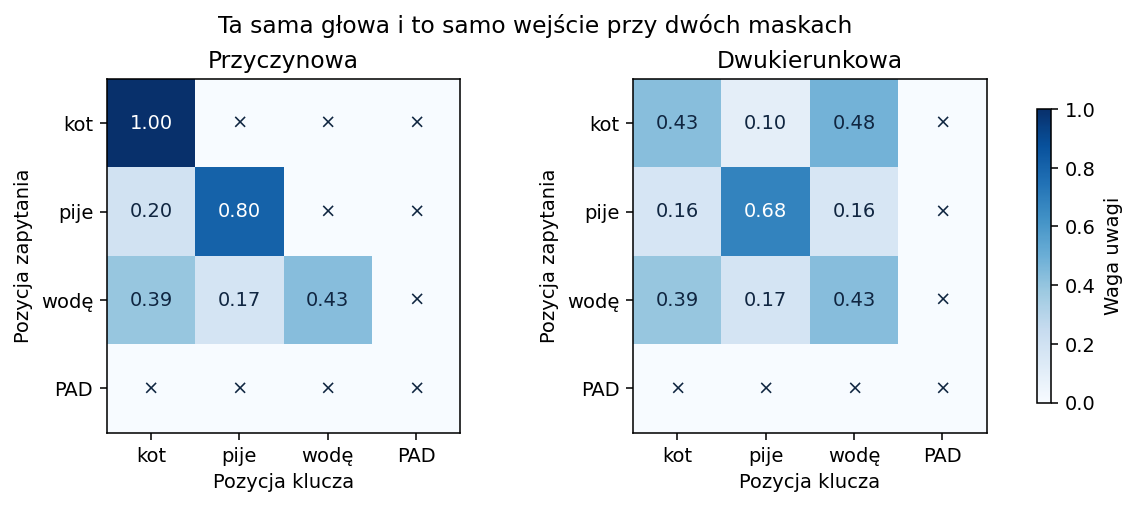

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.5), layout="constrained")
labels = np.array(names)[ids[0]]
for ax, label, weights, causal in zip(
    axes, ("Przyczynowa", "Dwukierunkowa"), (A, A_full), (True, False)
):
    mask = attention_mask(valid, causal)[0, 0]
    im = ax.imshow(weights[0, 0], vmin=0, vmax=1, cmap="Blues")
    ax.set(
        title=label, xlabel="Pozycja klucza", ylabel="Pozycja zapytania",
        xticks=range(T), yticks=range(T), xticklabels=labels, yticklabels=labels,
    )
    for t in range(T):
        for s in range(T):
            value = weights[0, 0, t, s]
            text = f"{value:.2f}" if mask[t, s] else "×"
            ax.text(s, t, text, ha="center", va="center",
                    color="white" if value > 0.65 else "#102641")
fig.colorbar(im, ax=axes, label="Waga uwagi", shrink=0.83)
fig.suptitle("Ta sama głowa i to samo wejście przy dwóch maskach")
plt.show()

## 6. Od bloku do następnego tokenu

Stos bloków nadal zwraca reprezentację $(B,T,D)$. Przy słowniku o rozmiarze $|\mathcal V|$ główka językowa stosuje tę samą projekcję $(D,|\mathcal V|)$ w każdej pozycji. Wynik ma kształt $(B,T,|\mathcal V|)$ i zawiera po jednym logicie na token słownika. Dla sekwencji `BOS kot pije wodę EOS` można przygotować parę

| Wejście $x$ | BOS | kot | pije | wodę |
| --- | --- | --- | --- | --- |
| Cel $y$ | kot | pije | wodę | EOS |

Logity z pozycji `pije` porównujemy z celem `wodę`. Maska przyczynowa kontroluje dostęp podczas forward. Osobna maska straty pomija cele PAD, gdy porównujemy logity z przesuniętymi identyfikatorami. Dla co najmniej jednego poprawnego celu średnią entropię krzyżową liczymy jako

$$
L = \frac{\sum_{b,t\,\colon\,m_{b,t}=1} \mathrm{CE}(z_{b,t},y_{b,t})}{\sum_{b,t}m_{b,t}},
\qquad
m_{b,t}=\mathbf 1\{\mathrm{valid}_{b,t}\land y_{b,t}\ne \mathrm{PAD}\}.
$$

Jeśli w batchu nie ma żadnej pary z $m=1$, mianownik wynosi zero. W takiej sytuacji można pominąć aktualizację parametrów dla batcha.

| Przypadek | Co wybiera długość lub maska |
| --- | --- |
| Jednokierunkowe RNN, klasyfikacja całej sekwencji | Przy paddingu z prawej z sekwencji stanów wybieramy $h_{b,\ell_b-1}$ dla długości $\ell_b>0$. Dla dwóch realnych tokenów i dwóch pól PAD wybieramy indeks 1. Próbkę pustą trzeba osobno obsłużyć lub wykluczyć. |
| Self-attention | W każdym wierszu wybieramy klucze dostępne według maski. Maska kluczy wyklucza PAD z ważonej sumy, a maska zapytań zeruje wiersze PAD. |
| Strata językowa | Uśredniamy CE po aktywnych parach wejście–cel. Realna pozycja wejściowa z celem PAD również wypada ze średniej. |

Gdy klasyfikator ma dostać jeden wektor z sekwencji attention, również wybieramy regułę odczytu, np. średnią po realnych tokenach. Pokazany blok dostarcza reprezentację każdej pozycji.

### Do wykonania

1. Dla sekwencji o dwóch rzeczywistych tokenach i dwóch polach PAD rozpisz wiersze 0, 1 i 2 maski przyczynowej. Sprawdź ich sumy po softmax w `A[1, 0, :3].sum(axis=-1)`.
2. W ręcznym przykładzie wybierz pełny kontekst. Oblicz pierwszy wiersz mapy oraz nowe $Y_0$. Następnie przelicz wynik kodem z sekcji 4, przekazując `causal=False` do `pre_ln_block`. Własny wynik porównaj z rachunkiem dwukierunkowym.
3. W teście przyszłości podmień token w pozycji 1. Wypisz, które reprezentacje powinny zachować wartości przy masce przyczynowej i które mogą się zmienić.

**Kontrola rachunku.** W zadaniu 1 wiersze dostępności to $(1,0,0,0)$, $(1,1,0,0)$ i $(0,0,0,0)$. Sumy wag wynoszą $1,1,0$. W zadaniu 2 pierwszy wiersz wag to $(1/2,1/2)$, poprawka uwagi wynosi $(0,0)$, a $Y_0=(1{,}25,2{,}5)$ w rachunku z $\varepsilon=0$. W zadaniu 3 gwarancja niezmienności obejmuje pozycję 0 oraz wyzerowane pola PAD. Pozycje 1 i 2 mogą się zmienić.

**Powiązanie z kursem.** Rozdział rozwija fragment o Transformerze z [RNN, LSTM i GRU](../deep_learning/4_CNN_RNN/Ch04_02_DLL_zajecia_rnn_lstm_gru_instructor.ipynb) oraz ćwiczenie `06_OD_GLOWY_DO_TRANSFORMERA` z pakietu dydaktycznego attention. Wybór konwencji pre-LN i test podmiany przyszłego tokenu nawiązują do tego ćwiczenia. Implementacja w NumPy, rachunek ręczny i test paddingu powstały na potrzeby tego rozdziału.